# 🧩 LangGraph: Subgraphs with Language Detection & Turkish Translation

### 📌 Overview
This notebook demonstrates **Subgraphs with Isolated State Schemas** in a multilingual pipeline:
1. **Language Detection (`detect_language`):** Analyzes the incoming question and detects the source language.
2. **Knowledge Generation (`generate_answer`):** Formulates an answer to the user's question.
3. **Child Subgraph (`subgraph`):** An isolated translation micro-workflow with its own private schema (`SubState`: `input_text` ➔ `translated_text`).
4. **State Bridge Function (`translate_answer`):** The parent node that maps the parent's generated answer into the child subgraph and populates the Turkish output (`answer_tr`).

---

### 🗺️ Architecture & State Mapping

```text
 ┌─────────────────────────────────────────────────────────────────────────────┐
 │ PARENT GRAPH (ParentState: question, detected_language, answer, answer_tr)  │
 │                                                                             │
 │  ┌─────────┐     ┌─────────────────┐     ┌─────────────────┐                │
 │  │  START  │ ──► │ detect_language │ ──► │ generate_answer │ ──┐            │
 │  └─────────┘     └─────────────────┘     └─────────────────┘   │            │
 │                                                                ▼            │
 │                                                     ┌─────────────────────┐ │
 │                                                     │  translate_answer   │ │
 │                                                     │   (State Bridge)    │ │
 │                                                     └──────────┬──────────┘ │
 │                                                                │ (Invoke)   │
 │                                                                ▼            │
 │                ┌──────────────────────────────────────────────────┐         │
 │                │ CHILD SUBGRAPH (SubState: input_text)            │         │
 │                │                                                  │         │
 │                │  ┌─────────┐   ┌──────────────────────┐   ┌─────┐│         │
 │                │  │  START  │──►│ translate_to_turkish │──►│ END ││         │
 │                │  └─────────┘   └──────────────────────┘   └─────┘│         │
 │                │                           │                      │         │
 │                └───────────────────────────┼──────────────────────┘         │
 │                                            │ (Returns: translated_text)     │
 │                                            ▼                                │
 │                                       ┌─────────┐                           │
 │                                       │   END   │                           │
 │                                       └─────────┘                           │
 └─────────────────────────────────────────────────────────────────────────────┘
```

In [1]:
import os
from typing import NotRequired, TypedDict
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

# Load environment variables
load_dotenv()

# Verify OpenRouter key
if not os.getenv("OPENROUTER_API_KEY"):
    raise ValueError(
        "OPENROUTER_API_KEY is missing. Please add it to your .env file: "
        "OPENROUTER_API_KEY=sk-or-v1-..."
    )

### 2. Initialize LLM via OpenRouter
We configure `ChatOpenAI` with `openrouter/free` at `temperature=0.3` for consistent language detection and natural translation.

In [2]:
model = ChatOpenAI(
    model="openrouter/free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    temperature=0.3,
)

### 3. Define Child Subgraph Schema (`SubState`)
The translation subgraph has an isolated, private schema. It knows nothing about questions or detected source languages—it only takes `input_text` and emits `translated_text`.

In [3]:
class SubState(TypedDict):
    input_text: str
    translated_text: NotRequired[str]

### 4. Build and Compile the Turkish Translation Subgraph
This child graph focuses purely on producing high-quality, natural Turkish translations.

In [4]:
def translate_to_turkish(state: SubState) -> dict:
    """Subgraph Node: Translates input text into fluent, natural Turkish."""
    messages = [
        (
            "system",
            "You are a professional translator specializing in Turkish. "
            "Translate the text into natural, fluent Turkish using proper technical grammar. "
            "Do not add preambles, notes, or explanations.",
        ),
        ("human", state["input_text"]),
    ]
    response = model.invoke(messages)
    return {"translated_text": str(response.content).strip()}


# Build and compile Child Subgraph
subgraph_builder = StateGraph(SubState)
subgraph_builder.add_node("translate_to_turkish", translate_to_turkish)
subgraph_builder.add_edge(START, "translate_to_turkish")
subgraph_builder.add_edge("translate_to_turkish", END)

subgraph = subgraph_builder.compile()

### 5. Standalone Subgraph Verification
We verify the translation subgraph in isolation before connecting it to the parent workflow.

Child Subgraph Test Output:
Özerk ajanlar, karmaşık iş akışlarını koordine etmek için grafikler kullanır.



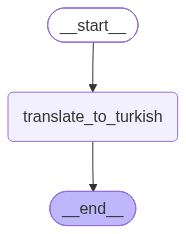

In [5]:
test_output = subgraph.invoke(
    {"input_text": "Autonomous agents use graphs to coordinate complex workflows."}
)
print(f"Child Subgraph Test Output:\n{test_output['translated_text']}\n")

# Render child topology
subgraph

### 6. Define Parent Graph Schema (`ParentState`)
The parent schema manages:
* `question`: The user's input prompt (any language).
* `detected_language`: The detected source language.
* `answer`: The generated answer in the source language.
* `answer_tr`: The Turkish translation returned by the child subgraph.

In [6]:
class ParentState(TypedDict):
    question: str
    detected_language: NotRequired[str]
    answer: NotRequired[str]
    answer_tr: NotRequired[str]

### 7. Define Parent Nodes & Subgraph Bridge Function
* **`detect_language`:** Identifies the language of the incoming question.
* **`generate_answer`:** Answers the question clearly.
* **`translate_answer` (Bridge Node):** Extracts `state["answer"]`, passes it to `subgraph.invoke()`, and maps the result back to `state["answer_tr"]`.

In [7]:
def detect_language(state: ParentState) -> dict:
    """Parent Node 1: Detects the language of the input question."""
    messages = [
        (
            "system",
            "Identify the language of the following text. Respond with ONLY the language name (e.g. English, German, French, Spanish, Turkish).",
        ),
        ("human", state["question"]),
    ]
    response = model.invoke(messages)
    return {"detected_language": str(response.content).strip()}


def generate_answer(state: ParentState) -> dict:
    """Parent Node 2: Formulates a concise explanation in 2-3 sentences."""
    messages = [
        ("system", "You are a concise, helpful technical assistant. Answer clearly in 2-3 sentences."),
        ("human", state["question"]),
    ]
    response = model.invoke(messages)
    return {"answer": str(response.content).strip()}


def translate_answer(state: ParentState) -> dict:
    """Parent Node 3: State Transformation Bridge that invokes the child subgraph."""
    # 1. Map Parent State -> Subgraph Input
    subgraph_input = {"input_text": state["answer"]}

    # 2. Invoke Child Subgraph
    subgraph_output = subgraph.invoke(subgraph_input)

    # 3. Map Subgraph Output -> Parent State Delta
    return {"answer_tr": subgraph_output["translated_text"]}

### 8. Build and Compile the Parent Graph
We connect: `START ➔ detect_language ➔ generate_answer ➔ translate_answer ➔ END`.

In [8]:
# Build and compile Parent Graph
parent_builder = StateGraph(ParentState)
parent_builder.add_node("detect_language", detect_language)
parent_builder.add_node("generate_answer", generate_answer)
parent_builder.add_node("translate_answer", translate_answer)

parent_builder.add_edge(START, "detect_language")
parent_builder.add_edge("detect_language", "generate_answer")
parent_builder.add_edge("generate_answer", "translate_answer")
parent_builder.add_edge("translate_answer", END)

parent_graph = parent_builder.compile()

### 9. Visualize Parent Graph Topology
Evaluating `parent_graph` renders the hierarchical pipeline.

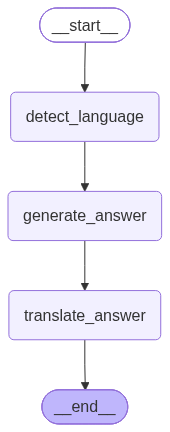

In [9]:
parent_graph

### 10. Execute the Multilingual Pipeline
We test the pipeline with questions in different languages (English and German). The graph automatically identifies the language, formulates the answer, and uses the child subgraph to translate it into Turkish.

In [10]:
# Test 1: English Prompt
print("=== TEST 1: ENGLISH INPUT ===")
test_en = parent_graph.invoke({"question": "What is reinforcement learning from human feedback (RLHF)?"})
print(f"Detected Language: {test_en['detected_language']}")
print(f"Original Answer:\n{test_en['answer']}\n")
print(f"Turkish Translation (via Subgraph):\n{test_en['answer_tr']}\n")

print("=" * 60)

# Test 2: German Prompt
print("=== TEST 2: GERMAN INPUT ===")
test_de = parent_graph.invoke({"question": "Was ist Quantenverschränkung in der Physik?"})
print(f"Detected Language: {test_de['detected_language']}")
print(f"Original Answer:\n{test_de['answer']}\n")
print(f"Turkish Translation (via Subgraph):\n{test_de['answer_tr']}")

=== TEST 1: ENGLISH INPUT ===
Detected Language: English
Original Answer:
RLHF is a technique used to align AI models with human preferences and values. Humans rank different model outputs to train a reward model, which the AI then optimizes for using reinforcement learning. This process helps reduce harmful, biased, or incorrect responses.

Turkish Translation (via Subgraph):
RLHF, insan tercihleri ve değerlerine yapay zekâ modellerini hizalamak için kullanılan bir tekniktir. İnsanlar, ödül modeli eğitmek için farklı model çıktılarını derecelendirir; ardından yapay zekâ bu modeli pekiştirici öğrenme kullanarak optimize eder. Bu süreç, zararlı, yanlıcı veya yanlış yanıtları azaltmaya yardımcı olur.

=== TEST 2: GERMAN INPUT ===
Detected Language: German
Original Answer:
Quantenverschränkung ist ein Phänomen, bei dem zwei oder mehr Teilchen so korreliert werden, dass der Zustand eines Teilchens unmittelbar den Zustand des anderen bestimmt, unabhängig von der Entfernung zwischen ihnen. D